In [1]:
from astraeus_io import *
import pandas as pd
from pyvis.network import Network
from matplotlib import  pyplot as plt

from astropy.cosmology import FlatLambdaCDM
import astropy.units as u

## Investigting data

In [3]:
fname='tree_0.dat'
metals=True
rockstarID=False

In [5]:
if rockstarID:
    names = ['ID', 'descID']
else:
    names = []
names += ['localID', 'localDescID', 'numprog', 'snapnum',
          'aexp', 'pos_x', 'pos_y', 'pos_z',
          'vel_x', 'vel_y', 'vel_z',
          'Mvir', 'Mvir_prog',
          'Rvir', 'velDisp', 'velMax', 'spin', 'aexplastmerger',
          'Mgas_ini', 'frac_Mgas_merger']
if metals:
    names += ['Mgas_new', 'Mgas_ej']
names += ['Mgas', 'Mstar', 'fesc', 'Nion', 'fej', 'feff', 'fg',
          'zreion', 'photHI_bg']
if metals:
    names += ['MZ', 'MZ_O', 'MZ_Fe',
              'MZ_ini', 'MZ_O_ini', 'MZ_Fe_ini',
              'MZ_new', 'MZ_O_new', 'MZ_Fe_new',
              'MZ_frac_merger', 'MZ_O_frac_merger', 'MZ_Fe_frac_merger',
              'MZ_ej', 'MZ_O_ej', 'MZ_Fe_ej',
              'Mdust']
if rockstarID:
    names += ['Padding']

if rockstarID:
    formats = ['i8', 'i8']
else:
    formats = []
formats += ['i4', 'i4', 'i4', 'i4',
            'f4', 'f4', 'f4', 'f4',
            'f4', 'f4', 'f4',
            'f4', 'f4',
            'f4', 'f4', 'f4', 'f4', 'f4',
            'f4', 'f4']
if metals:
    formats += ['f4', 'f4']
formats += ['f4', 'f4', 'f4', 'f4', 'f4', 'f4', 'f4',
            'f4', 'f4']
if metals:
    formats += ['f4', 'f4', 'f4',
                'f4', 'f4', 'f4',
                'f4', 'f4', 'f4',
                'f4', 'f4', 'f4',
                'f4', 'f4', 'f4',
                'f4']
if rockstarID:
    formats += ['f4']

dt = np.dtype({'names': names, 'formats': formats})

In [6]:
dt

dtype([('localID', '<i4'), ('localDescID', '<i4'), ('numprog', '<i4'), ('snapnum', '<i4'), ('aexp', '<f4'), ('pos_x', '<f4'), ('pos_y', '<f4'), ('pos_z', '<f4'), ('vel_x', '<f4'), ('vel_y', '<f4'), ('vel_z', '<f4'), ('Mvir', '<f4'), ('Mvir_prog', '<f4'), ('Rvir', '<f4'), ('velDisp', '<f4'), ('velMax', '<f4'), ('spin', '<f4'), ('aexplastmerger', '<f4'), ('Mgas_ini', '<f4'), ('frac_Mgas_merger', '<f4'), ('Mgas_new', '<f4'), ('Mgas_ej', '<f4'), ('Mgas', '<f4'), ('Mstar', '<f4'), ('fesc', '<f4'), ('Nion', '<f4'), ('fej', '<f4'), ('feff', '<f4'), ('fg', '<f4'), ('zreion', '<f4'), ('photHI_bg', '<f4'), ('MZ', '<f4'), ('MZ_O', '<f4'), ('MZ_Fe', '<f4'), ('MZ_ini', '<f4'), ('MZ_O_ini', '<f4'), ('MZ_Fe_ini', '<f4'), ('MZ_new', '<f4'), ('MZ_O_new', '<f4'), ('MZ_Fe_new', '<f4'), ('MZ_frac_merger', '<f4'), ('MZ_O_frac_merger', '<f4'), ('MZ_Fe_frac_merger', '<f4'), ('MZ_ej', '<f4'), ('MZ_O_ej', '<f4'), ('MZ_Fe_ej', '<f4'), ('Mdust', '<f4')])

In [7]:
ngtree, = np.fromfile(fname, dtype='i', count=1)
offset = np.dtype('i').itemsize

In [9]:
with open(fname, 'rb') as fnameID:
    fnameID.seek(offset)
    ngal = np.fromfile(fnameID, dtype='i', count=ngtree)
    # ngal = np.fromfile(fname, dtype='i', offset=offset, count=ngtree)
    offset += np.dtype('i').itemsize * ngtree
    fnameID.seek(offset)
    data = np.fromfile(fnameID, dtype=dt)

In [12]:
data['vel_z']

array([-122.22, -123.15, -123.42, ...,   10.23,    9.45,    9.25],
      shape=(18247983,), dtype=float32)

In [14]:
data[0]['vel_z']

np.float32(-122.22)

## Preparing data

In [2]:
galtree = read_treefile('tree_0.dat')

In [3]:
target_tree_id = 27590 # Tree with a few hundreds of galaxies
# target_tree_id = 0
tree_df = galtree[galtree['treeID'] == target_tree_id].copy()

In [4]:
cosmo = FlatLambdaCDM(H0=67.77 * u.km / u.s / u.Mpc,
                      Om0=0.307115,
                      Ob0=0.048206)

In [5]:
redshift_df = pd.read_csv('redshift_list.txt', sep='\\s+', comment='#', names=['n', 'z', 'a']) #
redshift_df['age_Gyr'] = redshift_df['z'].apply(lambda z: cosmo.age(z).to(u.Gyr).value)
redshift_df['age_yr'] = redshift_df['z'].apply(lambda z: cosmo.age(z).to(u.yr).value)
redshift_df['lookback_Gyr'] = redshift_df['z'].apply(lambda z: cosmo.lookback_time(z).to(u.Gyr).value)
snap_to_z = dict(zip(redshift_df['n'], redshift_df['z']))
snap_to_age = dict(zip(redshift_df['n'], redshift_df['age_Gyr']))

In [6]:
redshift_df['dT'] = redshift_df['age_yr'].diff()
snap_to_dt = dict(zip(redshift_df['n'], redshift_df['dT']))

In [7]:
tree_df['redshift'] = tree_df['snapnum'].map(snap_to_z)
tree_df['age'] = tree_df['snapnum'].map(snap_to_age)
tree_df['dt'] = tree_df['snapnum'].map(snap_to_dt)

In [8]:
tree_df['metallicity'] = tree_df['MZ_O']/tree_df['Mgas']

In [9]:
progenitors_map = tree_df.groupby('localDescID')['localID'].apply(list)

In [10]:
tree_df['progenitor_localIDs'] = tree_df['localID'].map(progenitors_map)
tree_df['progenitor_localIDs'] = tree_df['progenitor_localIDs'].apply(lambda d: d if isinstance(d, list) else [])

In [11]:
def get_sum_mstar_progs(prog_ids, mstar_lookup):
    if not prog_ids: # Empty list
        return 0.0
    # Retrieve masses and sum them
    return mstar_lookup.loc[prog_ids].sum()

In [12]:
mstar_lookup = tree_df.set_index('localID')['Mstar']

In [13]:
tree_df['sum_M_progenitors'] = tree_df['progenitor_localIDs'].apply(lambda x: get_sum_mstar_progs(x, mstar_lookup))

In [14]:
tree_df['SFR'] = (tree_df['Mstar'] - tree_df['sum_M_progenitors']) / tree_df['dt']

In [15]:
tree_df['prog_num'] = tree_df['progenitor_localIDs'].apply(len)

## Plotting

In [22]:
net = Network(height="2000px", width="100%", bgcolor="#222222", font_color="white", directed=True)

In [23]:
all_ids_in_tree = set(tree_df['localID'].astype(int))

for _, row in tree_df.iterrows():
    gal_id = int(row['localID'])
    snap = int(row['snapnum'])
    mass = float(row['Mvir'])

    # Customize node size based on mass (optional but helpful)
    # Using log10 because masses are huge
    node_size = (np.log10(mass) - 7) * 5 if mass > 0 else 5

    net.add_node(gal_id,
                 label=f"ID: {gal_id}",
                 title=f"Snap: {snap}\nMass: {mass:.2e}",
                 level=snap,
                 size=node_size)

In [24]:
for _, row in tree_df.iterrows():
    gal_id = int(row['localID'])
    desc_id = int(row['localDescID'])

    # ONLY add edge if the descendant ID exists in our filtered tree_df
    # and if the descendant is not -1 (the simulation end-of-line)
    if desc_id != -1 and desc_id in all_ids_in_tree:
        net.add_edge(gal_id, desc_id)

In [ ]:
net.set_options("""
var options = {
  "layout": {
    "hierarchical": {
      "enabled": true,
      "direction": "UD",
      "sortMethod": "directed"
    }
  },
  "physics": {
    "hierarchicalRepulsion": {
      "nodeDistance": 150
    }
  }
}
""")

net.show("merger_tree.html", notebook=False)

merger_tree.html


## Comparing different trees

In [16]:
tree_counts = galtree['treeID'].value_counts()

biggest_tree_id = tree_counts.idxmax()
num_galaxies = tree_counts.max()

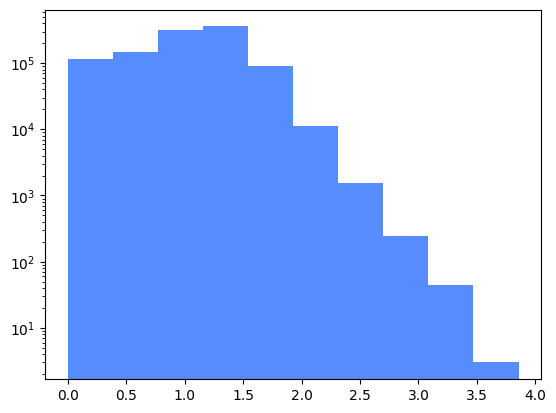

In [38]:
plt.hist(np.log10(tree_counts))
plt.yscale('log')


In [17]:
redshift_df = pd.read_csv('redshift_list.txt', sep='\s+', comment='#', names=['n', 'z', 'a']) #

snap_to_z = dict(zip(redshift_df['n'], redshift_df['z'])) #

<>:1: SyntaxWarning: invalid escape sequence '\s'
<>:1: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_458222/1593677100.py:1: SyntaxWarning: invalid escape sequence '\s'
  redshift_df = pd.read_csv('redshift_list.txt', sep='\s+', comment='#', names=['n', 'z', 'a']) #


In [18]:
tree_df['redshift'] = snap_to_z.get(tree_df['snapnum'], None)

TypeError: unhashable type: 'Series'

In [19]:

def track_descendants(full_df, start_id):
    """Traces the main descendant line for a specific galaxy ID."""
    lineage = []
    current_id = start_id

    while current_id != -1:
        # Find the row for the current ID
        row = full_df[full_df['localID'] == current_id]

        if row.empty:
            break

        galaxy_info = row.iloc[0].to_dict()
        # Add redshift to the dictionary
        galaxy_info['redshift'] = snap_to_z.get(galaxy_info['snapnum'], None) #
        lineage.append(galaxy_info)

        # Move to the next descendant
        current_id = int(galaxy_info['localDescID']) #

    return pd.DataFrame(lineage)

/tmp/ipykernel_458222/2401288331.py:21: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


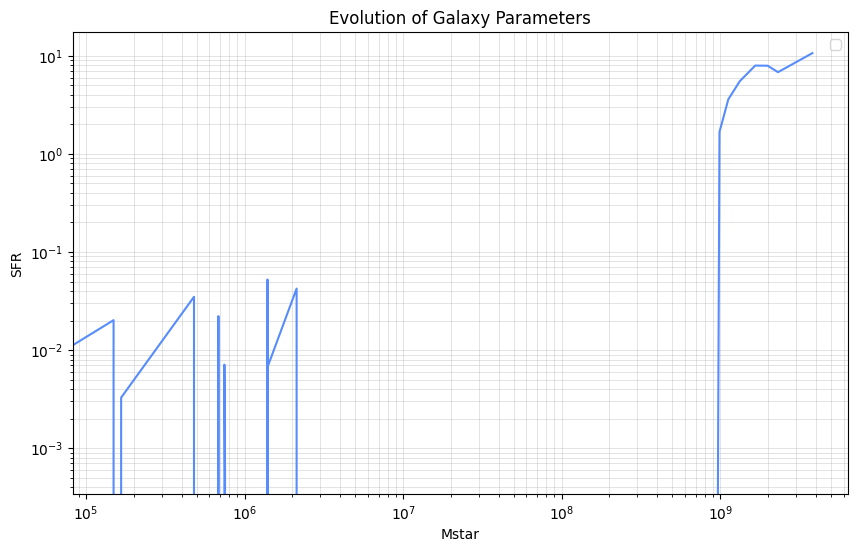

In [21]:

# 2. Extract a lineage (example: starting with ID 100)
lineage_df = track_descendants(tree_df, start_id=0)

lineage_df2 = track_descendants(tree_df, start_id=1234)

# 3. Visualize the evolution of parameters
plt.figure(figsize=(10, 6))
# plt.plot(lineage_df['redshift'], lineage_df['Mvir'], marker='o', label='Virial Mass')
# plt.plot(lineage_df['redshift'], lineage_df['Mstar'], marker='s', label='Stellar Mass')
l1 = 'Mstar'
l2 = 'SFR'
plt.plot(lineage_df[l1], lineage_df[l2])
# plt.plot(lineage_df2[l1], lineage_df2[l2])


# plt.yscale('log')
plt.xlabel(l1)
plt.ylabel(l2)
plt.title('Evolution of Galaxy Parameters')
# plt.gca().invert_xaxis() # High redshift on the left, low on the right
plt.legend()
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.yscale('log')
plt.xscale('log')
# plt.colorbar(label='Redshift')
plt.show()

## Adding progenitors

In [43]:
progenitors_map = tree_df.groupby('localDescID')['localID'].apply(list)

In [44]:
tree_df['progenitor_localIDs'] = tree_df['localID'].map(progenitors_map)
tree_df['progenitor_localIDs'] = tree_df['progenitor_localIDs'].apply(lambda d: d if isinstance(d, list) else [])

In [45]:
tree_df.columns

Index(['localID', 'localDescID', 'numprog', 'snapnum', 'aexp', 'pos_x',
       'pos_y', 'pos_z', 'vel_x', 'vel_y', 'vel_z', 'Mvir', 'Mvir_prog',
       'Rvir', 'velDisp', 'velMax', 'spin', 'aexplastmerger', 'Mgas_ini',
       'frac_Mgas_merger', 'Mgas_new', 'Mgas_ej', 'Mgas', 'Mstar', 'fesc',
       'Nion', 'fej', 'feff', 'fg', 'zreion', 'photHI_bg', 'MZ', 'MZ_O',
       'MZ_Fe', 'MZ_ini', 'MZ_O_ini', 'MZ_Fe_ini', 'MZ_new', 'MZ_O_new',
       'MZ_Fe_new', 'MZ_frac_merger', 'MZ_O_frac_merger', 'MZ_Fe_frac_merger',
       'MZ_ej', 'MZ_O_ej', 'MZ_Fe_ej', 'Mdust', 'treeID', 'redshift', 'age',
       'dt', 'metallicity', 'progenitor_localIDs', 'sum_M_progenitors', 'SFR',
       'prog_num'],
      dtype='str')

In [46]:
cosmo = FlatLambdaCDM(H0=67.77 * u.km / u.s / u.Mpc,
                      Om0=0.307115,
                      Ob0=0.048206)

In [47]:
tree_df['age_Gyr'] = tree_df['redshift'].apply(lambda z: cosmo.age(z).to(u.Gyr).value)